# Hovmoller of theoretical cold pool speed

In [41]:
import numpy as np
import matplotlib.pyplot as plt
import xarray as xr
from netCDF4 import Dataset, num2date, date2num
from datetime import datetime
from matplotlib.dates import DateFormatter
import pandas as pd 

import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.mpl.ticker import LongitudeFormatter, LatitudeFormatter
import matplotlib.ticker as mticker 
import os
import glob
import matplotlib.gridspec as gridspec

from metpy.units import units
import metpy
import wrf
import metpy.calc as mpcalc
from wrf import (to_np, interplevel, geo_bounds, getvar, smooth2d, get_cartopy, cartopy_xlim,
                 cartopy_ylim, latlon_coords, destagger)

In [2]:
os.chdir("/glade/campaign/univ/uncs0067/cold_pool_experiments/coldpool1")
os.getcwd()
plotsdir = '/glade/u/home/athornton/wrf_visualization/plots/coldpool1/benchmark_2018/'
datafiles = (sorted(glob.glob("wrfout_d03_*")))
numfiles=len(datafiles)
print(numfiles)
print(datafiles[0])

85
wrfout_d03_2018-08-25_06:00:00


In [28]:
time_series = []
times = []
for i in range(0,numfiles):
    wrf_out_data = xr.open_dataset(datafiles[i])  
    ncfile = Dataset(datafiles[i])
    
    #First, lets find the data data assocaited with all of them
    time = wrf_out_data['XTIME'][0].values
    datetime = time.astype(np.datetime64)
    ts = pd.to_datetime(str(datetime))
    d = ts.strftime('%Y-%m-%d %H:%M')
    Time=wrf.extract_times(ncfile, timeidx=0, method='cat', squeeze=True, cache=None, meta=False, do_xtime=False)
    timestr=(str(Time))
    # Set up one time string for plot titles, another for file names
    titletime=(timestr[0:10]+' '+timestr[11:16])
    filetime=(timestr[0:10]+'_'+timestr[11:13])
    times.append(timestr)
    
    print('WRF valid time: ', d)
    
    theta_pert = wrf_out_data['T'][0].metpy.quantify() # drop xtra dim and keep lowest levels
    qvapor = wrf_out_data['QVAPOR'][0].metpy.quantify()
    qcloud = wrf_out_data['QCLOUD'][0].metpy.quantify()
    qrain = wrf_out_data['QRAIN'][0].metpy.quantify()
    
    theta_full = theta_pert + 300*units('K')    # add 300K for full theta
    
    theta_bar = theta_full.mean(dim='west_east')      # average along latitude to get ambient theta
    theta_p = theta_full-theta_bar
    qv_bar = qvapor.mean(dim='west_east')             # average along latitude to get ambient qvapor
    #theta_neg = theta_pert.where(theta_pert < 0)      # extract only negative theta perturbations
    
    B = metpy.constants.earth_gravity * (theta_pert/theta_bar + 0.61*(qvapor-qv_bar)-qrain-qcloud)
    coldpool_mask = (B < 0)    
    B_masked = B.where(coldpool_mask)

    lats, lons = latlon_coords(wrf_out_data['P'])
    lats_np = to_np(lats)
    lons_np = to_np(lons)
    lats_np = lats_np[0,:,0]
    lons_np = lons_np[0,0,:]
    
    lat_min = 8.5
    lat_max = 9.5
    lon_min = np.min(lons_np)
    lon_max = np.max(lons_np)

    idx = np.where(lats_np <= lat_min)
    min_lat_idx = idx[0][-1]
    idx = np.where(lats_np <= lat_max)
    max_lat_idx = idx[0][-1]
    
    idx = np.where(lons_np <= lon_min)
    min_lon_idx = idx[0][-1]
    idx = np.where(lons_np <= lon_max)
    max_lon_idx = idx[0][-1]

    B_sfc = B_masked[0]
    B_latmean = B_sfc.sel(south_north=slice(min_lat_idx,max_lat_idx)).mean(dim='south_north')

    time_series.append(B_latmean)

WRF valid time:  2018-08-25 06:00
WRF valid time:  2018-08-25 06:30
WRF valid time:  2018-08-25 07:00
WRF valid time:  2018-08-25 07:30
WRF valid time:  2018-08-25 08:00
WRF valid time:  2018-08-25 08:30
WRF valid time:  2018-08-25 09:00
WRF valid time:  2018-08-25 09:30
WRF valid time:  2018-08-25 10:00
WRF valid time:  2018-08-25 10:30
WRF valid time:  2018-08-25 11:00
WRF valid time:  2018-08-25 11:30
WRF valid time:  2018-08-25 12:00
WRF valid time:  2018-08-25 12:30
WRF valid time:  2018-08-25 13:00
WRF valid time:  2018-08-25 13:30
WRF valid time:  2018-08-25 14:00
WRF valid time:  2018-08-25 14:30
WRF valid time:  2018-08-25 15:00
WRF valid time:  2018-08-25 15:30
WRF valid time:  2018-08-25 16:00
WRF valid time:  2018-08-25 16:30
WRF valid time:  2018-08-25 17:00
WRF valid time:  2018-08-25 17:30
WRF valid time:  2018-08-25 18:00
WRF valid time:  2018-08-25 18:30
WRF valid time:  2018-08-25 19:00
WRF valid time:  2018-08-25 19:30
WRF valid time:  2018-08-25 20:00
WRF valid time

In [38]:
time_series

[<xarray.DataArray (west_east: 2490)> Size: 10kB
 <Quantity([-0.08936821 -0.08935066 -0.08933434 ... -0.10542601 -0.10566725
  -0.10522062], 'meter / second ** 2')>
 Coordinates:
     XTIME    datetime64[ns] 8B 2018-08-25T06:00:00
 Dimensions without coordinates: west_east
 Attributes:
     FieldType:    104
     MemoryOrder:  XYZ
     stagger:      ,
 <xarray.DataArray (west_east: 2490)> Size: 10kB
 <Quantity([-0.08544785 -0.08541156 -0.08538301 ... -0.10650196 -0.10646059
  -0.10635489], 'meter / second ** 2')>
 Coordinates:
     XTIME    datetime64[ns] 8B 2018-08-25T06:30:00
 Dimensions without coordinates: west_east
 Attributes:
     FieldType:    104
     MemoryOrder:  XYZ
     stagger:      ,
 <xarray.DataArray (west_east: 2490)> Size: 10kB
 <Quantity([-0.08211967 -0.08207466 -0.08203319 ... -0.10317207 -0.10309525
  -0.1029945 ], 'meter / second ** 2')>
 Coordinates:
     XTIME    datetime64[ns] 8B 2018-08-25T07:00:00
 Dimensions without coordinates: west_east
 Attributes:
     

In [30]:
# change times to pandas DATETIME format for ease of plotting
times_pd = pd.to_datetime(times)
start_date = times_pd[0]
end_date = times_pd[-1]

Text(1.0, 1.0, '2018-08-25 06:00:00 - 2018-08-27 00:00:00')

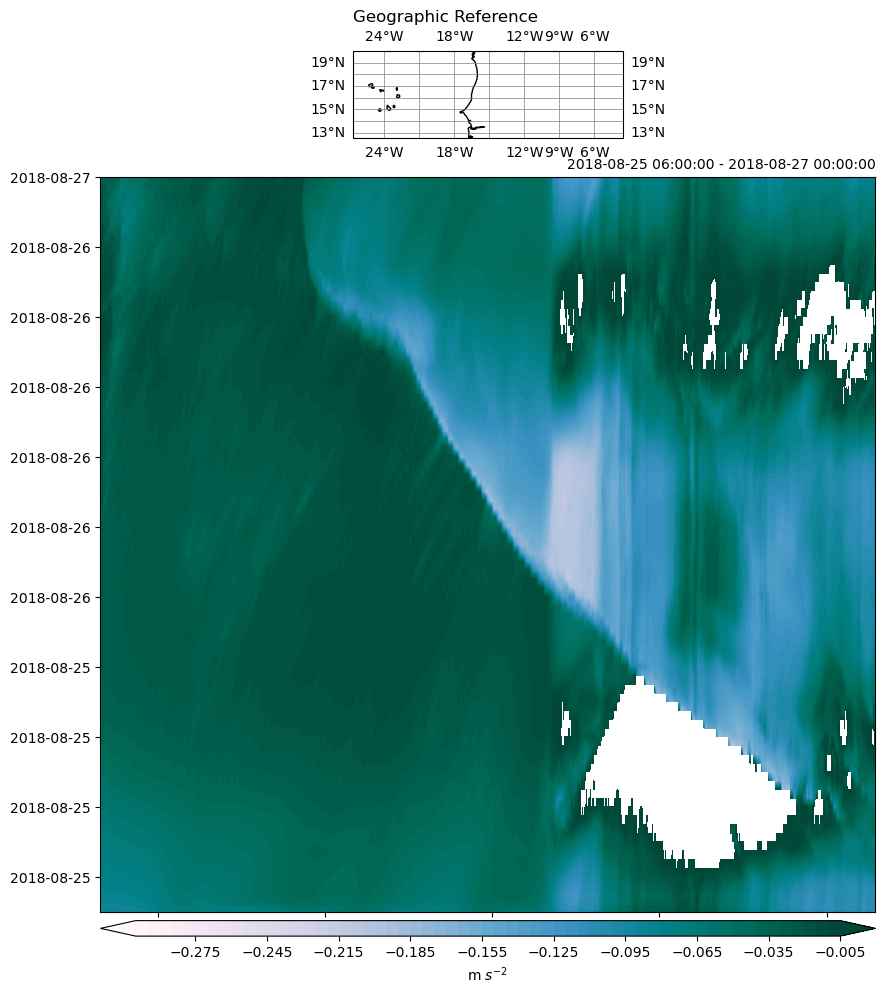

In [43]:
# Fig quality
plt.rcParams['savefig.dpi'] = 255

fig = plt.figure(figsize=(10, 13)) 

# Use gridspec to help size elements of plot; small top plot and big bottom plot
gs = gridspec.GridSpec(nrows=2, ncols=1, height_ratios=[1, 10], hspace=0.08)

minlon = -80.
maxlon = 10.
minlat = 12.5
maxlat = 20.

# Get the longitude range from the Hovmöller plot data 
lon_min = np.min(lons_np)
lon_max = np.max(lons_np)
# lon_min = minlon
# lon_max = maxlon

# Top plot for geographic reference (small map)
ax1 = fig.add_subplot(gs[0, 0], projection=ccrs.PlateCarree())
ax1.set_extent([lon_min, lon_max, minlat, maxlat], crs=ccrs.PlateCarree())  # Match longitude extent
ax1.gridlines(crs=ccrs.PlateCarree(), draw_labels=True,
                  linewidth=0.5, color='gray')

# Add boundaries for map reference
ax1.add_feature(cfeature.COASTLINE.with_scale('50m'))
ax1.add_feature(cfeature.LAKES.with_scale('50m'), color='black', linewidths=0.5)

# Set some titles
plt.title('Geographic Reference', loc='left')

# Bottom plot for Hovmöller diagram
ax2 = fig.add_subplot(gs[1, 0])

# Plot of chosen variable averaged over latitude 
clevs = np.arange(-0.3, 0, 0.005)
cf = ax2.contourf(lons_np, times_pd, time_series, levels=clevs, cmap="PuBuGn", extend='both')

date_form = DateFormatter('%Y-%m-%d')
ax2.yaxis.set_major_formatter(date_form)

# Colorbars
cbar = plt.colorbar(cf, orientation='horizontal', pad=0.01, aspect=50)
cbar.set_label('m $s^{-2}$')

# Set some titles for Hovmöller diagram
#plt.suptitle('Theoretical Cold pool speed\n '+title, fontsize=15, weight='bold', y=0.93)
plt.title(str(start_date) +' - ' + str(end_date),
          loc='right', fontsize=10)

#plt.savefig(plotsdir+'winds_vort600_hov_fluxON_'+str(start_date)+'.png')
#plt.savefig(plotsdir+'winds_vort600_hov_'+str(start_date)+'.png')